# Phân Tích Thực Nghiệm Chi Phí Ghi Trong Apache IoTDB 1.3.3

Notebook này thực hiện toàn bộ quy trình xử lý thống kê, kiểm định giả thuyết, ước lượng mô hình hồi quy / ANOVA và kết xuất biểu đồ cho đề tài:
> **"Đo lường thực nghiệm ảnh hưởng của thứ tự và kích thước dữ liệu đến chi phí ghi vào Apache IoTDB"**

### Phương pháp ước lượng Khoảng tin cậy 95% (95% CI)
- **Phương pháp chính (Student's *t*-distribution):** Với mỗi tổ hợp tham số gồm $n \ge 10$ lần lặp độc lập theo hạt giống (`seed`), khoảng tin cậy 95% của kỳ vọng được tính theo phân phối Student-$t$ với $n - 1$ bậc tự do:
  $$\text{CI}_{95\%} = \bar{x} \pm t_{0.975,\, n-1} \cdot \frac{s}{\sqrt{n}}$$
- **Phương pháp đối chứng phi tham số (Percentile Bootstrap):** Với các chỉ số có thể lệch phải (như độ trễ đuôi `lat_p99_ms`), notebook tính thêm khoảng tin cậy Bootstrap ($B = 4.000$ lần lấy mẫu lại có hoàn lại, `seed = 42`) để đối chiếu độ vững thống kê.

In [1]:
from __future__ import annotations

import json
import warnings
from pathlib import Path
from typing import Any, Dict, List

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore", category=FutureWarning)

# Resolve repository root whether executed from repo root or notebooks/
CWD = Path.cwd().resolve()
REPO_ROOT = CWD.parent if CWD.name == "notebooks" else CWD
DATA_CSV = REPO_ROOT / "data" / "processed" / "runs.csv"
PILOT_CSV = REPO_ROOT / "data" / "processed" / "pilot_runs.csv"
FIG_DIR = REPO_ROOT / "report" / "figures"
OUT_SUMMARY_CSV = REPO_ROOT / "data" / "processed" / "summary_by_cell.csv"
OUT_MODELS_JSON = REPO_ROOT / "data" / "processed" / "statistical_models.json"

FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 300,
    "font.sans-serif": ["DejaVu Sans", "Arial", "Segoe UI"],
    "axes.unicode_minus": False,
    "axes.grid": True,
    "grid.alpha": 0.28,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 8.5,
})
sns.set_palette("deep")

df = pd.read_csv(DATA_CSV)
print(f"Loaded {len(df)} experimental runs across {df.shape[1]} columns.")
print("Breakdown by primary experiment_group:")
print(df["experiment_group"].value_counts())
assert (df["error_requests"] == 0).all(), "Found runs with RPC errors!"


Loaded 670 experimental runs across 75 columns.
Breakdown by primary experiment_group:
experiment_group
main_matrix          360
concurrency_study    200
delay_dist_study      60
delay_mean_study      50
Name: count, dtype: int64


## 1. Thống Kê Mô Tả & Khoảng Tin Cậy 95% Cho Mọi Tổ Hợp Tham Số
Tính trung bình (`mean`), độ lệch chuẩn hiệu chỉnh (`std`, `ddof=1`), bán kính khoảng tin cậy 95% theo Student-$t$ (`ci95_half`), cận dưới/trên (`ci95_low`, `ci95_high`) và đối chiếu với Bootstrap 95% CI.

In [2]:
# Derived analytical columns per run
df["ooo_pct"] = (df["ooo_ratio"] * 100.0).round(0).astype(int)
df["flushed_total_bytes"] = df["flushed_seq_bytes"] + df["flushed_unseq_bytes"]
df["unseq_byte_share_pct"] = np.where(
    df["flushed_total_bytes"] > 0,
    df["flushed_unseq_bytes"] / df["flushed_total_bytes"] * 100.0,
    0.0,
)
df["wal_amp"] = df["wal_written_bytes"] / df["logical_bytes"]
df["seq_flush_amp"] = df["flushed_seq_bytes"] / df["logical_bytes"]
df["unseq_flush_amp"] = df["flushed_unseq_bytes"] / df["logical_bytes"]
df["comp_write_amp"] = df["compaction_written_bytes"] / df["logical_bytes"]

CELL_COLS = ["ooo_ratio", "ooo_pct", "batch_size", "num_clients", "delay_dist", "delay_mean_ms", "total_records"]
KEY_METRICS = [
    "wa_storage",
    "wa_disk",
    "wa_tsfile_rewrite",
    "throughput_rps",
    "effective_throughput_rps",
    "lat_p50_ms",
    "lat_p95_ms",
    "lat_p99_ms",
    "lat_per_1k_rows_p50_ms",
    "cpu_ms_per_1k_records",
    "flushed_seq_files",
    "flushed_unseq_files",
    "unseq_byte_share_pct",
    "compaction_cross_count",
    "compaction_total_count",
    "compaction_written_bytes",
    "compaction_overlap_chunks",
    "comp_write_amp",
    "wal_amp",
    "seq_flush_amp",
    "unseq_flush_amp",
    "datanode_heap_peak_mb",
    "container_ram_peak_mb",
]


def bootstrap_ci95(values: np.ndarray, n_boot: int = 4000, seed: int = 42) -> tuple[float, float]:
    rng = np.random.default_rng(seed)
    n = len(values)
    if n < 2 or np.allclose(values, values[0]):
        v = float(np.mean(values))
        return v, v
    idx = rng.integers(0, n, size=(n_boot, n))
    means = values[idx].mean(axis=1)
    low, high = np.percentile(means, [2.5, 97.5])
    return float(low), float(high)


summary_rows: List[Dict[str, Any]] = []
for keys, sub in df.groupby(CELL_COLS, sort=True):
    n = len(sub)
    row_out: Dict[str, Any] = dict(zip(CELL_COLS, keys))
    row_out["n_reps"] = int(n)
    row_out["experiment_group"] = str(sub["experiment_group"].iloc[0])
    t_crit = float(stats.t.ppf(0.975, df=max(n - 1, 1))) if n > 1 else 0.0

    for m in KEY_METRICS:
        arr = sub[m].to_numpy(dtype=np.float64)
        mean_v = float(np.mean(arr))
        std_v = float(np.std(arr, ddof=1)) if n > 1 else 0.0
        sem_v = std_v / np.sqrt(n) if n > 1 else 0.0
        half_t = t_crit * sem_v
        row_out[f"{m}_mean"] = mean_v
        row_out[f"{m}_std"] = std_v
        row_out[f"{m}_ci95_half"] = half_t
        row_out[f"{m}_ci95_low"] = mean_v - half_t
        row_out[f"{m}_ci95_high"] = mean_v + half_t
        if m in ("wa_storage", "wa_disk", "throughput_rps", "lat_p99_ms", "cpu_ms_per_1k_records"):
            b_low, b_high = bootstrap_ci95(arr)
            row_out[f"{m}_boot_low"] = b_low
            row_out[f"{m}_boot_high"] = b_high

    summary_rows.append(row_out)

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(OUT_SUMMARY_CSV, index=False)
print(f"Computed summary statistics for {len(summary_df)} parameter cells (min reps={summary_df['n_reps'].min()}, max reps={summary_df['n_reps'].max()}).")
summary_df[["ooo_pct", "batch_size", "num_clients", "delay_dist", "delay_mean_ms", "n_reps", "wa_storage_mean", "wa_storage_ci95_half", "throughput_rps_mean", "throughput_rps_ci95_half"]].head(12)


Computed summary statistics for 67 parameter cells (min reps=10, max reps=10).


,ooo_pct,batch_size,num_clients,delay_dist,delay_mean_ms,n_reps,wa_storage_mean,wa_storage_ci95_half,throughput_rps_mean,throughput_rps_ci95_half
0,0,1,4,exponential,25000.0,10,4.971546,0.222811,3355.739176,333.910198
1,0,10,4,exponential,25000.0,10,2.443844,0.273501,15621.658291,939.693269
2,0,100,1,exponential,25000.0,10,2.501946,0.000061,67608.750577,9410.280465
3,0,100,4,exponential,25000.0,10,2.537206,0.083439,84709.423890,16516.613627
4,0,100,16,exponential,25000.0,10,2.353098,0.254014,106690.943745,27330.442594
5,0,1000,1,exponential,25000.0,10,3.013278,0.240664,19940.037930,823.613333
6,0,1000,4,exponential,25000.0,10,2.512453,0.078431,60031.387488,8984.120460
7,0,1000,16,exponential,25000.0,10,2.219788,0.250976,98516.590424,29904.359389
8,0,10000,4,exponential,25000.0,10,2.253694,0.254760,158741.956661,76780.935657
9,0,50000,1,exponential,25000.0,10,2.178310,0.272043,128883.598102,29621.123453


## 2. Biểu Đồ Chi Phí Ghi Theo `ooo_ratio`, `batch_size`, `num_clients` Và Heatmap Tương Tác
Tất cả thanh sai số (error bars) trên biểu đồ thể hiện **Khoảng tin cậy 95% theo phân phối Student-$t$** ($n = 10$ lần lặp mỗi điểm).

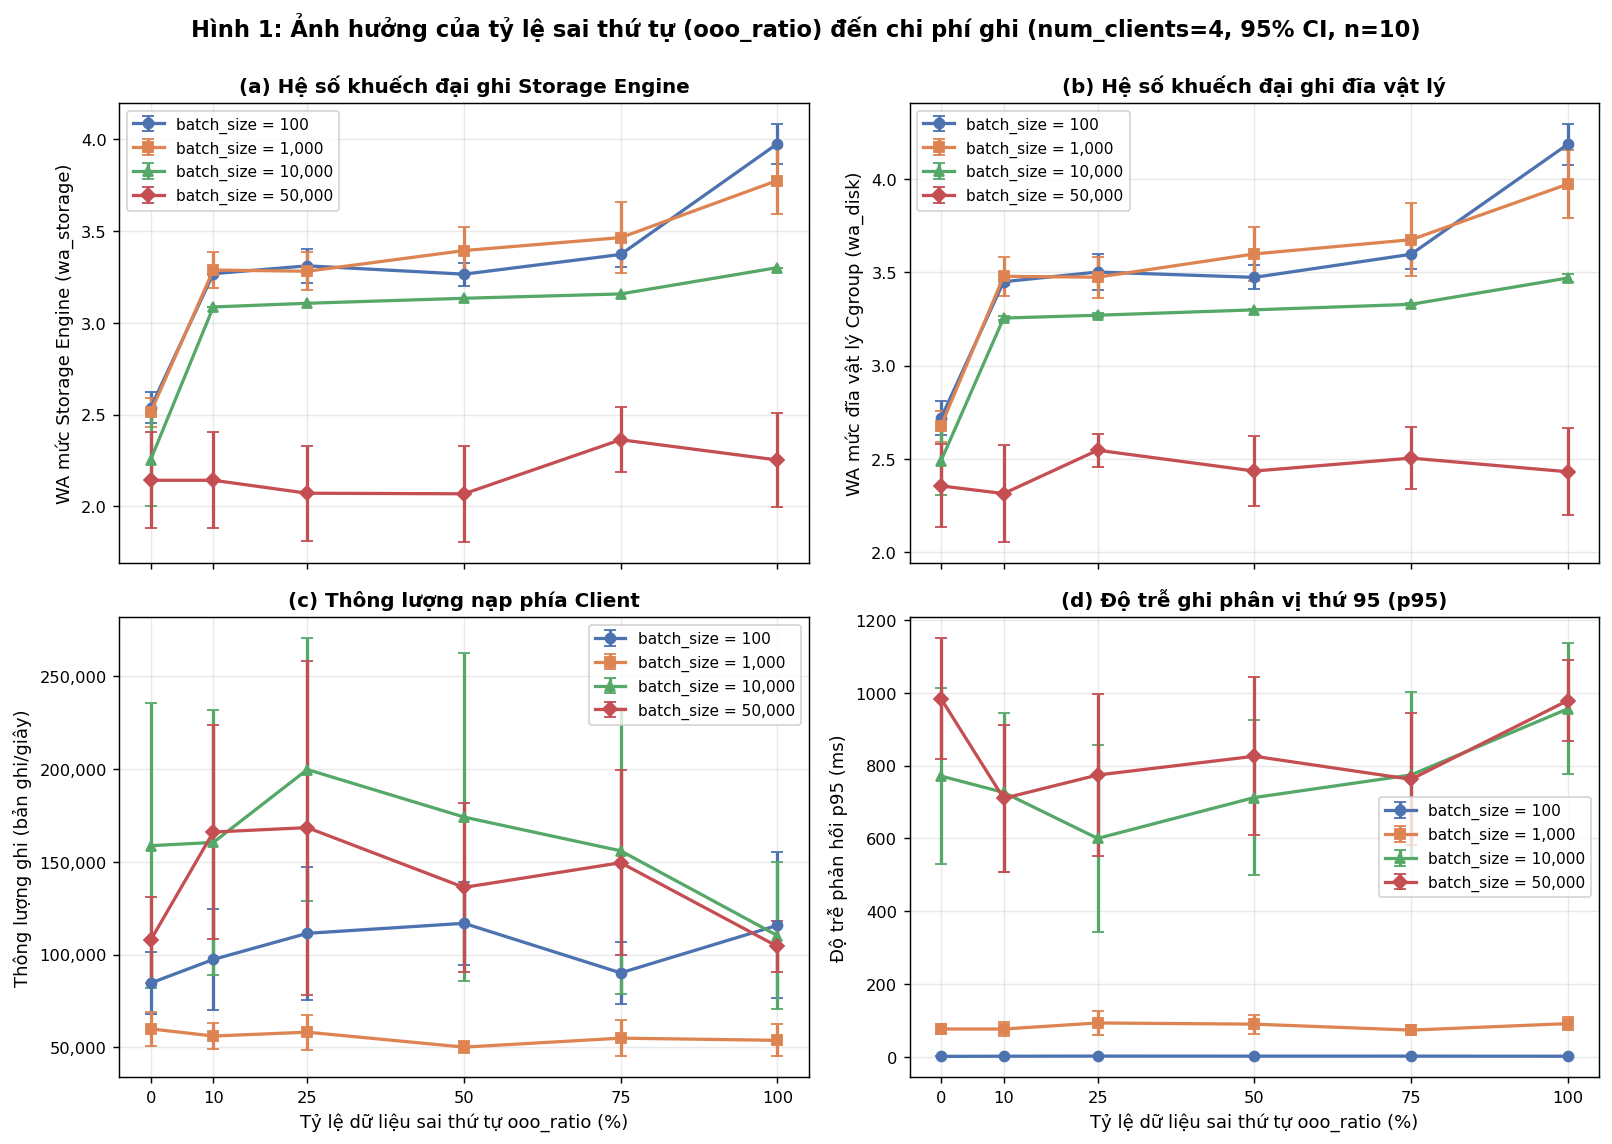

In [3]:
# Slice 1: Full 6x6 Factorial (ooo_ratio x batch_size at num_clients=4, exponential, delay_mean=25000ms)
main_sub = summary_df[
    (summary_df["num_clients"] == 4)
    & (summary_df["delay_dist"] == "exponential")
    & (np.isclose(summary_df["delay_mean_ms"], 25_000.0))
].copy()

# --- FIGURE 1: Write Cost vs ooo_ratio (for tablet batch sizes 100..50,000) ---
fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.8), sharex=True)
tablet_batches = [100, 1_000, 10_000, 50_000]
markers = {100: "o", 1_000: "s", 10_000: "^", 50_000: "D"}

panels_f1 = [
    ("wa_storage", "WA mức Storage Engine (wa_storage)", "(a) Hệ số khuếch đại ghi Storage Engine"),
    ("wa_disk", "WA mức đĩa vật lý Cgroup (wa_disk)", "(b) Hệ số khuếch đại ghi đĩa vật lý"),
    ("throughput_rps", "Thông lượng ghi (bản ghi/giây)", "(c) Thông lượng nạp phía Client"),
    ("lat_p95_ms", "Độ trễ phản hồi p95 (ms)", "(d) Độ trễ ghi phân vị thứ 95 (p95)"),
]

for ax, (metric, ylabel, title) in zip(axes.flat, panels_f1):
    for bsz in tablet_batches:
        s = main_sub[main_sub["batch_size"] == bsz].sort_values("ooo_pct")
        ax.errorbar(
            s["ooo_pct"],
            s[f"{metric}_mean"],
            yerr=s[f"{metric}_ci95_half"],
            marker=markers[bsz],
            linewidth=1.8,
            markersize=5.5,
            capsize=3.5,
            label=f"batch_size = {bsz:,}",
        )
    ax.set_title(title, fontweight="bold")
    ax.set_ylabel(ylabel)
    ax.set_xticks([0, 10, 25, 50, 75, 100])
    if metric in ("throughput_rps",):
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
    ax.legend(loc="best", frameon=True)

axes[1, 0].set_xlabel("Tỷ lệ dữ liệu sai thứ tự ooo_ratio (%)")
axes[1, 1].set_xlabel("Tỷ lệ dữ liệu sai thứ tự ooo_ratio (%)")
fig.suptitle(
    "Hình 1: Ảnh hưởng của tỷ lệ sai thứ tự (ooo_ratio) đến chi phí ghi (num_clients=4, 95% CI, n=10)",
    fontsize=12.5,
    fontweight="bold",
    y=0.995,
)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig1_cost_vs_ooo_ratio.png", bbox_inches="tight")
plt.show()


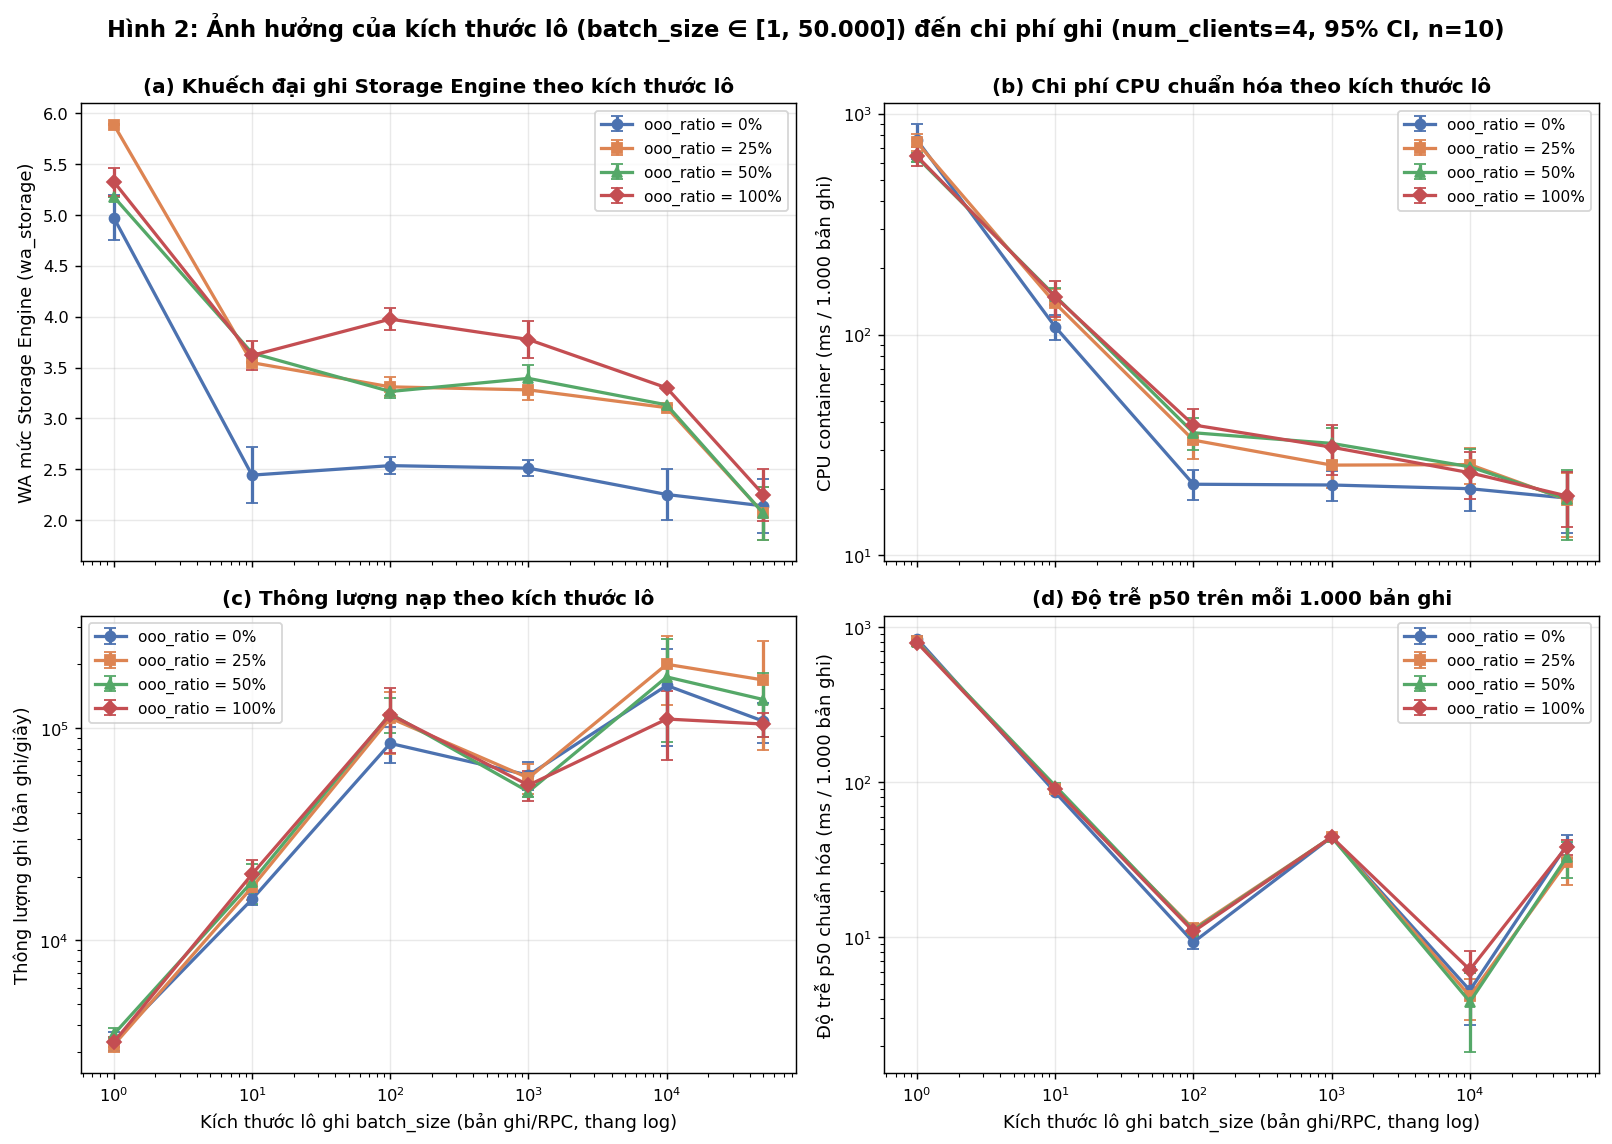

In [4]:
# --- FIGURE 2: Write Cost vs batch_size (across 5 orders of magnitude: 1 to 50,000) ---
fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.8), sharex=True)
sel_ooo = [0, 25, 50, 100]
ooo_markers = {0: "o", 25: "s", 50: "^", 100: "D"}

panels_f2 = [
    ("wa_storage", "WA mức Storage Engine (wa_storage)", "(a) Khuếch đại ghi Storage Engine theo kích thước lô", False),
    ("cpu_ms_per_1k_records", "CPU container (ms / 1.000 bản ghi)", "(b) Chi phí CPU chuẩn hóa theo kích thước lô", True),
    ("throughput_rps", "Thông lượng ghi (bản ghi/giây)", "(c) Thông lượng nạp theo kích thước lô", True),
    ("lat_per_1k_rows_p50_ms", "Độ trễ p50 chuẩn hóa (ms / 1.000 bản ghi)", "(d) Độ trễ p50 trên mỗi 1.000 bản ghi", True),
]

for ax, (metric, ylabel, title, logy) in zip(axes.flat, panels_f2):
    for op in sel_ooo:
        s = main_sub[main_sub["ooo_pct"] == op].sort_values("batch_size")
        ax.errorbar(
            s["batch_size"],
            s[f"{metric}_mean"],
            yerr=s[f"{metric}_ci95_half"],
            marker=ooo_markers[op],
            linewidth=1.8,
            markersize=5.5,
            capsize=3.5,
            label=f"ooo_ratio = {op}%",
        )
    ax.set_xscale("log")
    if logy:
        ax.set_yscale("log")
    ax.set_title(title, fontweight="bold")
    ax.set_ylabel(ylabel)
    ax.legend(loc="best", frameon=True)

axes[1, 0].set_xlabel("Kích thước lô ghi batch_size (bản ghi/RPC, thang log)")
axes[1, 1].set_xlabel("Kích thước lô ghi batch_size (bản ghi/RPC, thang log)")
fig.suptitle(
    "Hình 2: Ảnh hưởng của kích thước lô (batch_size ∈ [1, 50.000]) đến chi phí ghi (num_clients=4, 95% CI, n=10)",
    fontsize=12.5,
    fontweight="bold",
    y=0.995,
)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig2_cost_vs_batch_size.png", bbox_inches="tight")
plt.show()


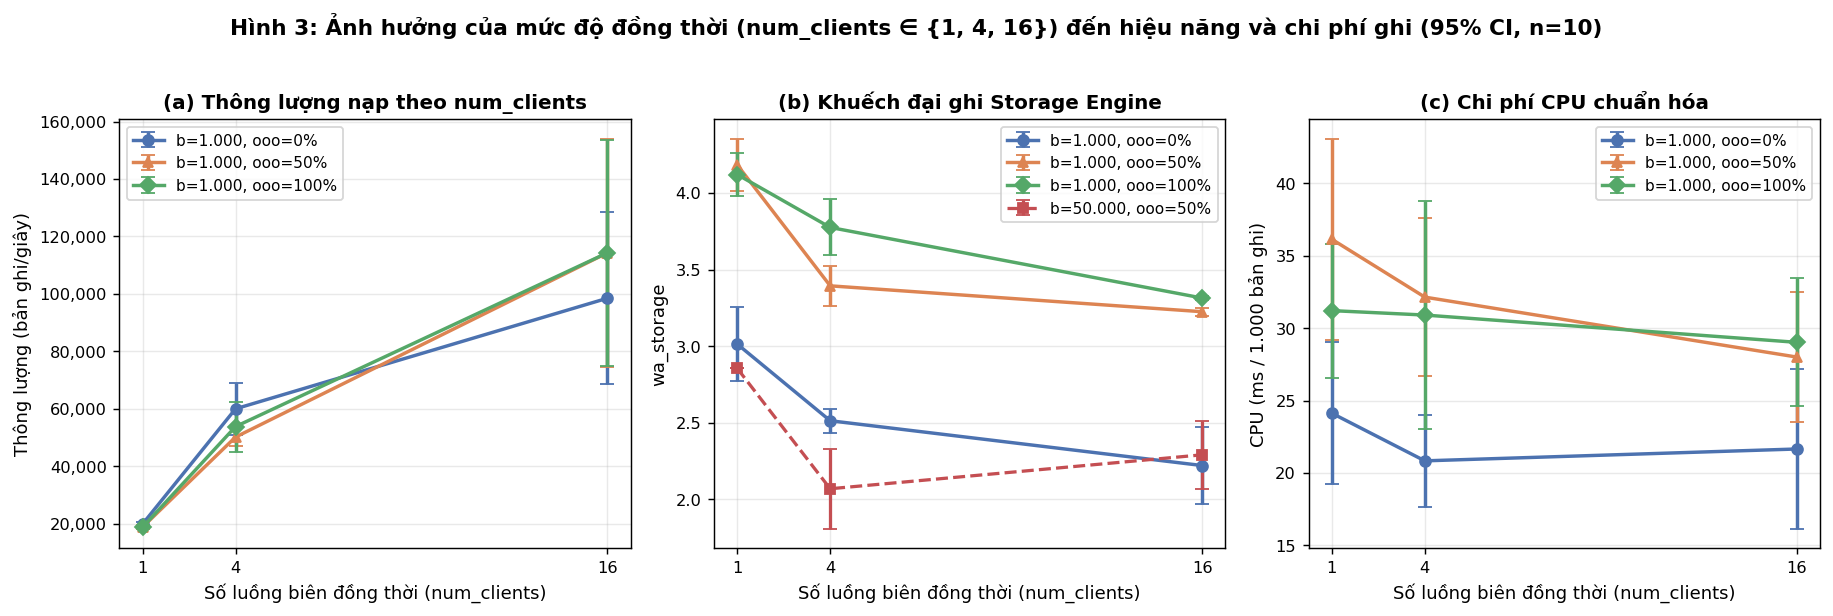

In [5]:
# --- FIGURE 3: Concurrency Scaling vs num_clients ({1, 4, 16}) ---
conc_sub = summary_df[
    (summary_df["batch_size"].isin([100, 1_000, 50_000]))
    & (summary_df["ooo_pct"].isin([0, 50, 100]))
    & (summary_df["delay_dist"] == "exponential")
    & (np.isclose(summary_df["delay_mean_ms"], 25_000.0))
].copy()

fig, axes = plt.subplots(1, 3, figsize=(14.2, 4.6))
conc_Slice = conc_sub[conc_sub["batch_size"] == 1_000]

for op, mk in [(0, "o"), (50, "^"), (100, "D")]:
    s = conc_Slice[conc_Slice["ooo_pct"] == op].sort_values("num_clients")
    axes[0].errorbar(
        s["num_clients"], s["throughput_rps_mean"], yerr=s["throughput_rps_ci95_half"],
        marker=mk, linewidth=1.9, capsize=4, label=f"b=1.000, ooo={op}%"
    )
    axes[1].errorbar(
        s["num_clients"], s["wa_storage_mean"], yerr=s["wa_storage_ci95_half"],
        marker=mk, linewidth=1.9, capsize=4, label=f"b=1.000, ooo={op}%"
    )
    axes[2].errorbar(
        s["num_clients"], s["cpu_ms_per_1k_records_mean"], yerr=s["cpu_ms_per_1k_records_ci95_half"],
        marker=mk, linewidth=1.9, capsize=4, label=f"b=1.000, ooo={op}%"
    )

# Also overlay batch_size=50,000 at ooo=50% to highlight client-partition interaction!
s50k = conc_sub[(conc_sub["batch_size"] == 50_000) & (conc_sub["ooo_pct"] == 50)].sort_values("num_clients")
axes[1].errorbar(
    s50k["num_clients"], s50k["wa_storage_mean"], yerr=s50k["wa_storage_ci95_half"],
    marker="s", linestyle="--", linewidth=1.8, capsize=4, label="b=50.000, ooo=50%"
)

for ax in axes:
    ax.set_xticks([1, 4, 16])
    ax.set_xlabel("Số luồng biên đồng thời (num_clients)")
    ax.legend(loc="best", frameon=True)

axes[0].set_title("(a) Thông lượng nạp theo num_clients", fontweight="bold")
axes[0].set_ylabel("Thông lượng (bản ghi/giây)")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
axes[1].set_title("(b) Khuếch đại ghi Storage Engine", fontweight="bold")
axes[1].set_ylabel("wa_storage")
axes[2].set_title("(c) Chi phí CPU chuẩn hóa", fontweight="bold")
axes[2].set_ylabel("CPU (ms / 1.000 bản ghi)")

fig.suptitle(
    "Hình 3: Ảnh hưởng của mức độ đồng thời (num_clients ∈ {1, 4, 16}) đến hiệu năng và chi phí ghi (95% CI, n=10)",
    fontsize=12,
    fontweight="bold",
    y=1.02,
)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig3_cost_vs_num_clients.png", bbox_inches="tight")
plt.show()


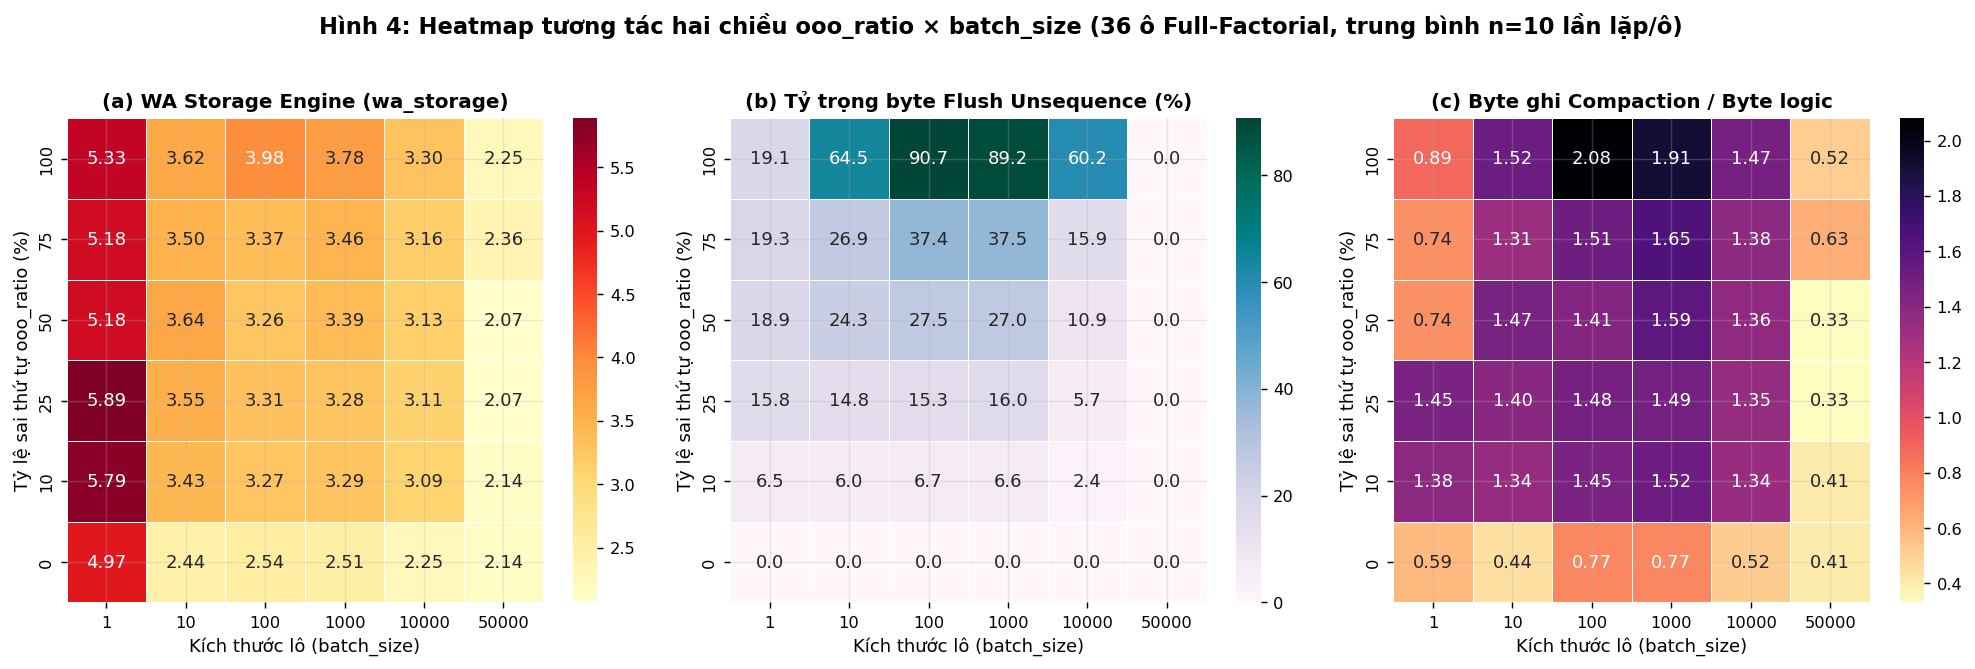

In [6]:
# --- FIGURE 4: 6x6 Interaction Heatmaps (ooo_ratio x batch_size at num_clients=4) ---
fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.0))

hm_specs = [
    ("wa_storage_mean", "(a) WA Storage Engine (wa_storage)", "YlOrRd", ".2f"),
    ("unseq_byte_share_pct_mean", "(b) Tỷ trọng byte Flush Unsequence (%)", "PuBuGn", ".1f"),
    ("comp_write_amp_mean", "(c) Byte ghi Compaction / Byte logic", "magma_r", ".2f"),
]

for ax, (col, title, cmap, fmt) in zip(axes, hm_specs):
    piv = main_sub.pivot(index="ooo_pct", columns="batch_size", values=col)
    piv = piv.sort_index(ascending=False)
    sns.heatmap(
        piv,
        annot=True,
        fmt=fmt,
        cmap=cmap,
        cbar=True,
        linewidths=0.5,
        ax=ax,
    )
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Kích thước lô (batch_size)")
    ax.set_ylabel("Tỷ lệ sai thứ tự ooo_ratio (%)")

fig.suptitle(
    "Hình 4: Heatmap tương tác hai chiều ooo_ratio × batch_size (36 ô Full-Factorial, trung bình n=10 lần lặp/ô)",
    fontsize=12.5,
    fontweight="bold",
    y=1.02,
)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig4_heatmap_ooo_x_batch.png", bbox_inches="tight")
plt.show()


## 3. Phân Rã Cơ Chế Nội Tại LSM-tree & Thí Nghiệm Phụ (`delay_dist`, `delay_mean`)
Đối chiếu trực tiếp chi phí ghi với các bộ đếm nội tại của Apache IoTDB: WAL, Flush `sequence` vs `unsequence`, `CrossSpaceCompaction`, số `CHUNK_OVERLAP_OR_MODIFIED` trích từ nhật ký DataNode, hình dạng phân bố trễ và ngưỡng cửa sổ thời gian.

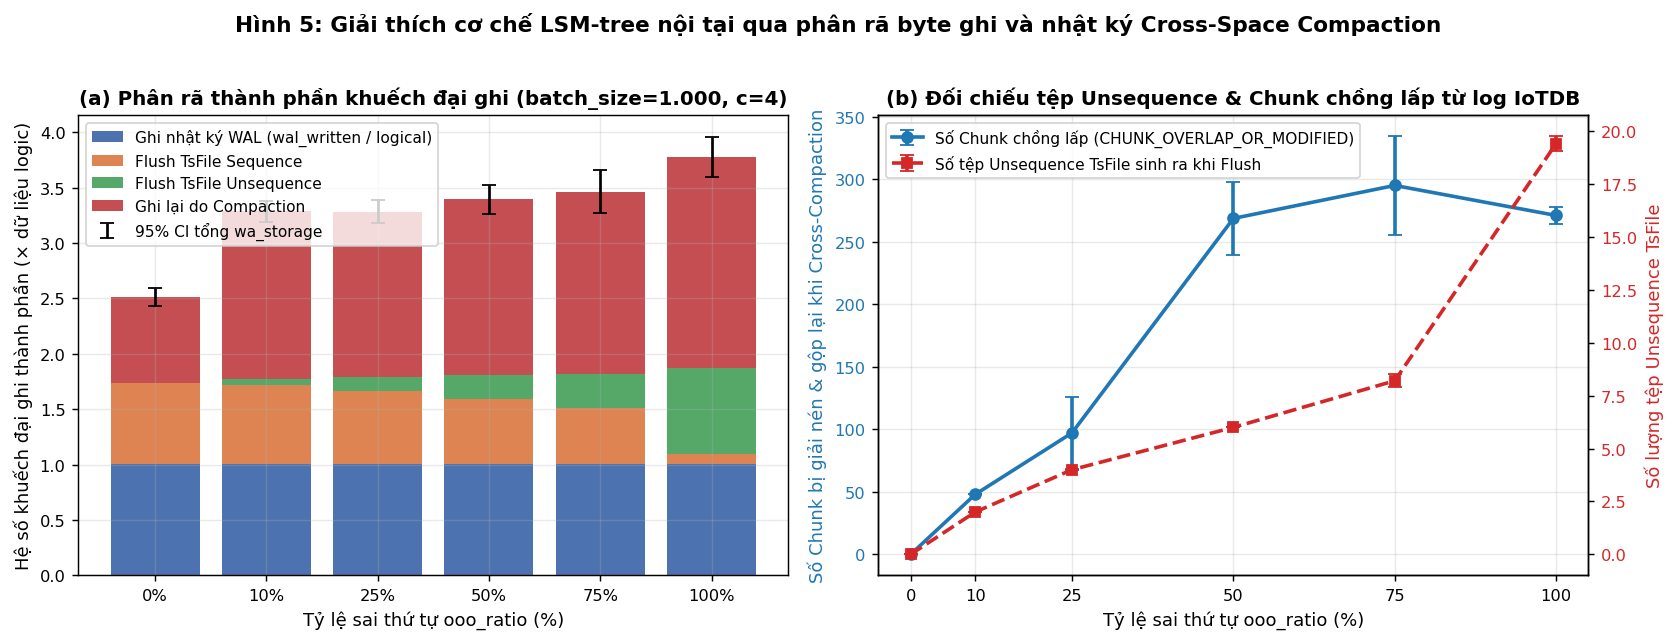

In [7]:
# --- FIGURE 5: LSM-tree Write Amplification Decomposition & Chunk Overlap ---
b1k = main_sub[main_sub["batch_size"] == 1_000].sort_values("ooo_pct")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.0, 4.8))

x_pos = np.arange(len(b1k))
labels = [f"{p}%" for p in b1k["ooo_pct"]]
w_wal = b1k["wal_amp_mean"].to_numpy()
w_seq = b1k["seq_flush_amp_mean"].to_numpy()
w_unseq = b1k["unseq_flush_amp_mean"].to_numpy()
w_comp = b1k["comp_write_amp_mean"].to_numpy()

ax1.bar(x_pos, w_wal, label="Ghi nhật ký WAL (wal_written / logical)")
ax1.bar(x_pos, w_seq, bottom=w_wal, label="Flush TsFile Sequence")
ax1.bar(x_pos, w_unseq, bottom=w_wal + w_seq, label="Flush TsFile Unsequence")
ax1.bar(x_pos, w_comp, bottom=w_wal + w_seq + w_unseq, label="Ghi lại do Compaction")
ax1.errorbar(
    x_pos,
    b1k["wa_storage_mean"],
    yerr=b1k["wa_storage_ci95_half"],
    fmt="none",
    ecolor="black",
    capsize=4,
    linewidth=1.5,
    label="95% CI tổng wa_storage",
)
ax1.set_xticks(x_pos)
ax1.set_xticklabels(labels)
ax1.set_xlabel("Tỷ lệ sai thứ tự ooo_ratio (%)")
ax1.set_ylabel("Hệ số khuếch đại ghi thành phần (× dữ liệu logic)")
ax1.set_title("(a) Phân rã thành phần khuếch đại ghi (batch_size=1.000, c=4)", fontweight="bold")
ax1.legend(loc="upper left", frameon=True)

color_left = "#1f77b4"
color_right = "#d62728"
ax2.errorbar(
    b1k["ooo_pct"],
    b1k["compaction_overlap_chunks_mean"],
    yerr=b1k["compaction_overlap_chunks_ci95_half"],
    color=color_left,
    marker="o",
    linewidth=2.0,
    capsize=4,
    label="Số Chunk chồng lấp (CHUNK_OVERLAP_OR_MODIFIED)",
)
ax2.set_xlabel("Tỷ lệ sai thứ tự ooo_ratio (%)")
ax2.set_ylabel("Số Chunk bị giải nén & gộp lại khi Cross-Compaction", color=color_left)
ax2.tick_params(axis="y", labelcolor=color_left)
ax2.set_xticks([0, 10, 25, 50, 75, 100])

ax2_r = ax2.twinx()
ax2_r.errorbar(
    b1k["ooo_pct"],
    b1k["flushed_unseq_files_mean"],
    yerr=b1k["flushed_unseq_files_ci95_half"],
    color=color_right,
    marker="s",
    linestyle="--",
    linewidth=2.0,
    capsize=4,
    label="Số tệp Unsequence TsFile sinh ra khi Flush",
)
ax2_r.set_ylabel("Số lượng tệp Unsequence TsFile", color=color_right)
ax2_r.tick_params(axis="y", labelcolor=color_right)
ax2_r.grid(False)
ax2.set_title("(b) Đối chiếu tệp Unsequence & Chunk chồng lấp từ log IoTDB", fontweight="bold")

lines1, labels1 = ax2.get_legend_handles_labels()
lines2, labels2 = ax2_r.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, loc="upper left", frameon=True)

fig.suptitle(
    "Hình 5: Giải thích cơ chế LSM-tree nội tại qua phân rã byte ghi và nhật ký Cross-Space Compaction",
    fontsize=12,
    fontweight="bold",
    y=1.02,
)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig5_lsm_internals_decomposition.png", bbox_inches="tight")
plt.show()


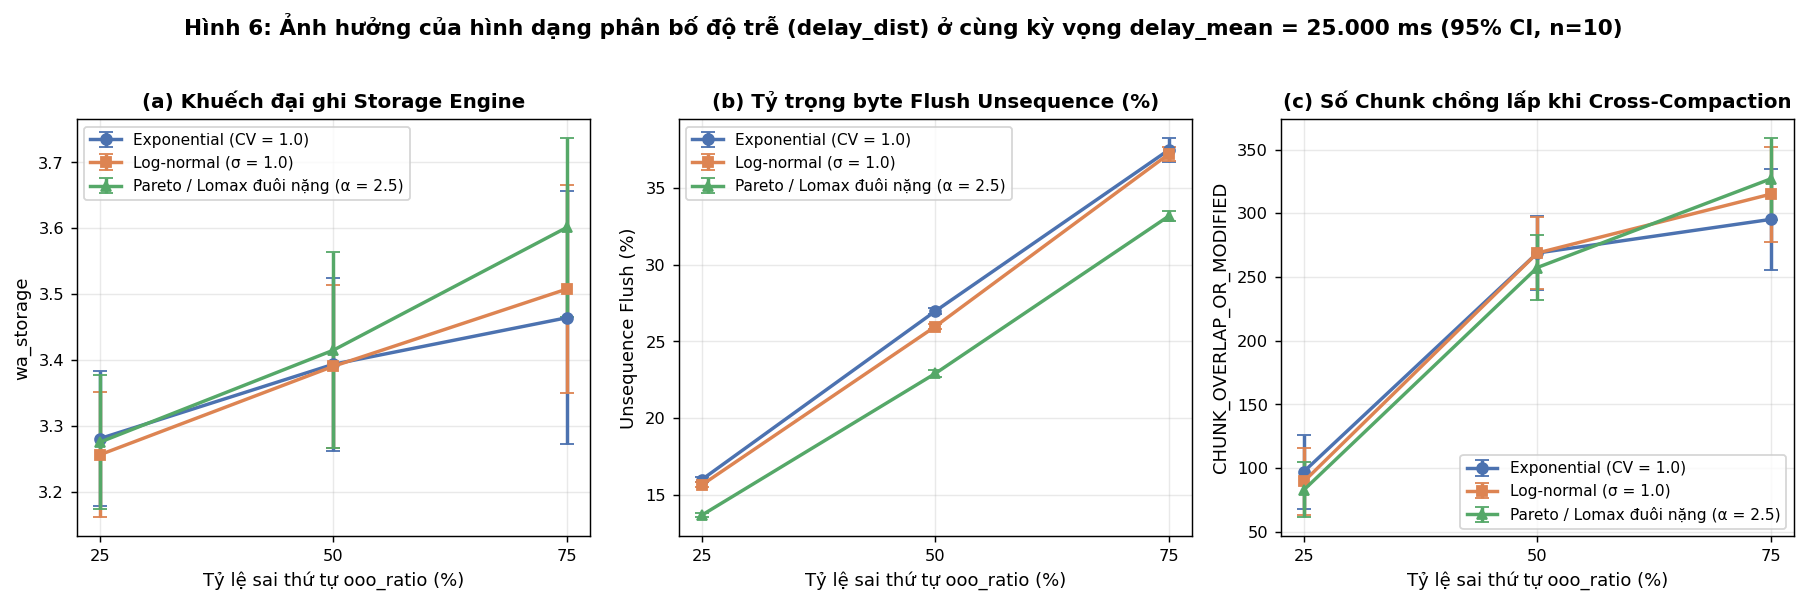

In [8]:
# --- FIGURE 6: Delay Distribution Sub-Experiment (exponential vs lognormal vs pareto) ---
ddist_sub = summary_df[
    (summary_df["batch_size"] == 1_000)
    & (summary_df["num_clients"] == 4)
    & (summary_df["ooo_pct"].isin([25, 50, 75]))
    & (np.isclose(summary_df["delay_mean_ms"], 25_000.0))
].copy()

fig, axes = plt.subplots(1, 3, figsize=(14.0, 4.5))
dist_styles = [
    ("exponential", "Exponential (CV = 1.0)", "o"),
    ("lognormal", "Log-normal (σ = 1.0)", "s"),
    ("pareto", "Pareto / Lomax đuôi nặng (α = 2.5)", "^"),
]

for dist_key, dist_label, mk in dist_styles:
    s = ddist_sub[ddist_sub["delay_dist"] == dist_key].sort_values("ooo_pct")
    axes[0].errorbar(
        s["ooo_pct"], s["wa_storage_mean"], yerr=s["wa_storage_ci95_half"],
        marker=mk, linewidth=1.9, capsize=4, label=dist_label
    )
    axes[1].errorbar(
        s["ooo_pct"], s["unseq_byte_share_pct_mean"], yerr=s["unseq_byte_share_pct_ci95_half"],
        marker=mk, linewidth=1.9, capsize=4, label=dist_label
    )
    axes[2].errorbar(
        s["ooo_pct"], s["compaction_overlap_chunks_mean"], yerr=s["compaction_overlap_chunks_ci95_half"],
        marker=mk, linewidth=1.9, capsize=4, label=dist_label
    )

for ax in axes:
    ax.set_xticks([25, 50, 75])
    ax.set_xlabel("Tỷ lệ sai thứ tự ooo_ratio (%)")
    ax.legend(loc="best", frameon=True)

axes[0].set_title("(a) Khuếch đại ghi Storage Engine", fontweight="bold")
axes[0].set_ylabel("wa_storage")
axes[1].set_title("(b) Tỷ trọng byte Flush Unsequence (%)", fontweight="bold")
axes[1].set_ylabel("Unsequence Flush (%)")
axes[2].set_title("(c) Số Chunk chồng lấp khi Cross-Compaction", fontweight="bold")
axes[2].set_ylabel("CHUNK_OVERLAP_OR_MODIFIED")

fig.suptitle(
    "Hình 6: Ảnh hưởng của hình dạng phân bố độ trễ (delay_dist) ở cùng kỳ vọng delay_mean = 25.000 ms (95% CI, n=10)",
    fontsize=12,
    fontweight="bold",
    y=1.02,
)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig6_delay_dist_comparison.png", bbox_inches="tight")
plt.show()


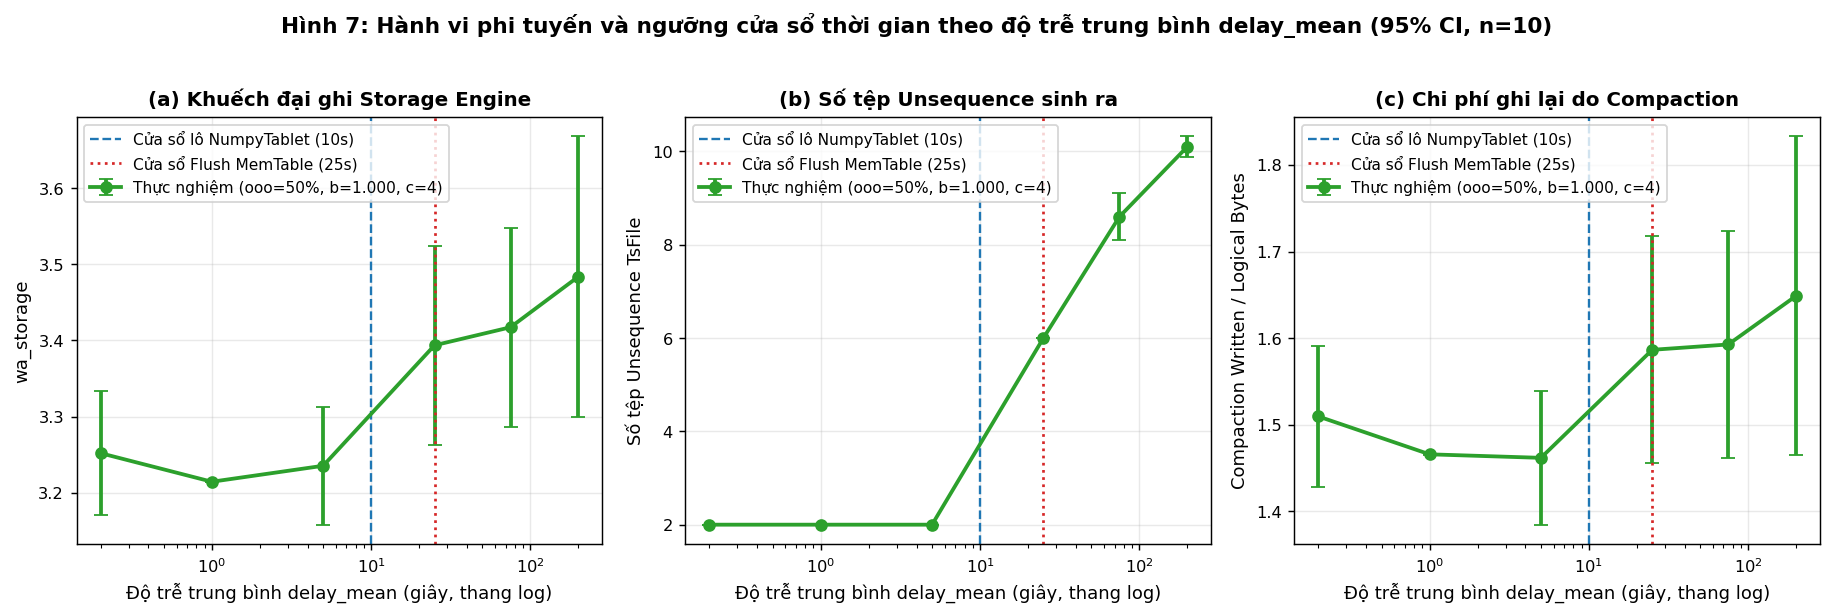

In [9]:
# --- FIGURE 7: Non-linear Threshold Sweep across delay_mean_ms ---
dmean_sub = summary_df[
    (summary_df["batch_size"] == 1_000)
    & (summary_df["num_clients"] == 4)
    & (summary_df["ooo_pct"] == 50)
    & (summary_df["delay_dist"] == "exponential")
].sort_values("delay_mean_ms")

fig, axes = plt.subplots(1, 3, figsize=(14.2, 4.6))

for ax, (col, ci_col, ylabel, title) in zip(
    axes,
    [
        ("wa_storage_mean", "wa_storage_ci95_half", "wa_storage", "(a) Khuếch đại ghi Storage Engine"),
        ("flushed_unseq_files_mean", "flushed_unseq_files_ci95_half", "Số tệp Unsequence TsFile", "(b) Số tệp Unsequence sinh ra"),
        ("comp_write_amp_mean", "comp_write_amp_ci95_half", "Compaction Written / Logical Bytes", "(c) Chi phí ghi lại do Compaction"),
    ],
):
    ax.errorbar(
        dmean_sub["delay_mean_ms"] / 1000.0,
        dmean_sub[col],
        yerr=dmean_sub[ci_col],
        marker="o",
        color="#2ca02c",
        linewidth=2.1,
        capsize=4,
        label="Thực nghiệm (ooo=50%, b=1.000, c=4)",
    )
    ax.axvline(10.0, color="#1f77b4", linestyle="--", linewidth=1.3, label="Cửa sổ lô NumpyTablet (10s)")
    ax.axvline(25.0, color="#d62728", linestyle=":", linewidth=1.5, label="Cửa sổ Flush MemTable (25s)")
    ax.set_xscale("log")
    ax.set_xlabel("Độ trễ trung bình delay_mean (giây, thang log)")
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontweight="bold")
    ax.legend(loc="best", frameon=True)

fig.suptitle(
    "Hình 7: Hành vi phi tuyến và ngưỡng cửa sổ thời gian theo độ trễ trung bình delay_mean (95% CI, n=10)",
    fontsize=12,
    fontweight="bold",
    y=1.02,
)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig7_delay_mean_threshold.png", bbox_inches="tight")
plt.show()


## 4. Định Lượng Quan Hệ Hồi Quy (Tuyến Tính & Log-Log) Và Kiểm Định Tương Tác ANOVA
Thực hiện:
1. **Hồi quy OLS tuyến tính và bậc hai** đánh giá độ dốc và tính bão hòa phi tuyến của `wa_storage`, `wa_disk` theo `ooo_ratio`.
2. **Hồi quy thang Log-Log ($\log_2 - \log_2$)** định lượng hệ số co giãn (elasticity): *khi `ooo_ratio` hoặc `batch_size` tăng gấp đôi ($\times 2$), chi phí ghi và thông lượng thay đổi bao nhiêu lần (kèm 95% CI)*.
3. **Phân tích phương sai đa nhân tố (Two-Way & Three-Way Type-II ANOVA)** kiểm định ý nghĩa thống kê của các tác động chính và tương tác `ooo_ratio × batch_size`, `ooo_ratio × num_clients`, `batch_size × num_clients`, kèm hệ số kích thước hiệu ứng $\eta^2$.

In [10]:
model_results: Dict[str, Any] = {}

# Raw observations for main 6x6 matrix (num_clients=4, exponential, delay_mean=25000, 360 runs)
raw_main = df[
    (df["num_clients"] == 4)
    & (df["delay_dist"] == "exponential")
    & (np.isclose(df["delay_mean_ms"], 25_000.0))
].copy()

# 4.1 Linear & Quadratic OLS on batch_size=1000 (60 runs)
raw_b1k = raw_main[raw_main["batch_size"] == 1_000].copy()
ols_lin = smf.ols("wa_storage ~ ooo_ratio", data=raw_b1k).fit()
ols_quad = smf.ols("wa_storage ~ ooo_ratio + I(ooo_ratio**2)", data=raw_b1k).fit()

ci_lin = ols_lin.conf_int().loc["ooo_ratio"].tolist()
ci_quad_1 = ols_quad.conf_int().loc["ooo_ratio"].tolist()
ci_quad_2 = ols_quad.conf_int().loc["I(ooo_ratio ** 2)"].tolist()

model_results["ols_wa_vs_ooo_b1000"] = {
    "linear_intercept": float(ols_lin.params["Intercept"]),
    "linear_slope": float(ols_lin.params["ooo_ratio"]),
    "linear_slope_ci95": [float(ci_lin[0]), float(ci_lin[1])],
    "linear_r2": float(ols_lin.rsquared),
    "linear_p": float(ols_lin.pvalues["ooo_ratio"]),
    "quad_b1": float(ols_quad.params["ooo_ratio"]),
    "quad_b1_ci95": [float(ci_quad_1[0]), float(ci_quad_1[1])],
    "quad_b2": float(ols_quad.params["I(ooo_ratio ** 2)"]),
    "quad_b2_ci95": [float(ci_quad_2[0]), float(ci_quad_2[1])],
    "quad_r2": float(ols_quad.rsquared),
    "quad_b2_p": float(ols_quad.pvalues["I(ooo_ratio ** 2)"]),
}

# 4.2 Log-Log Regression: when ooo_ratio doubles (x2) for ooo_ratio > 0 (b in {100, 1000, 10000})
raw_ooo_pos = raw_main[(raw_main["ooo_ratio"] > 0) & (raw_main["batch_size"] == 1_000)].copy()
raw_ooo_pos["log2_ooo"] = np.log2(raw_ooo_pos["ooo_ratio"])
raw_ooo_pos["log2_wa_storage"] = np.log2(raw_ooo_pos["wa_storage"])
raw_ooo_pos["log2_wa_disk"] = np.log2(raw_ooo_pos["wa_disk"])
# Excess write amplification above sequential baseline (wa_storage - mean(wa_storage at ooo=0))
seq_baseline_b1k = float(raw_b1k[raw_b1k["ooo_ratio"] == 0.0]["wa_storage"].mean())
raw_ooo_pos["excess_wa"] = np.maximum(raw_ooo_pos["wa_storage"] - seq_baseline_b1k, 1e-4)
raw_ooo_pos["log2_excess_wa"] = np.log2(raw_ooo_pos["excess_wa"])

loglog_wa_ooo = smf.ols("log2_wa_storage ~ log2_ooo", data=raw_ooo_pos).fit()
elast_wa = float(loglog_wa_ooo.params["log2_ooo"])
elast_wa_ci = loglog_wa_ooo.conf_int().loc["log2_ooo"].tolist()

loglog_excess_ooo = smf.ols("log2_excess_wa ~ log2_ooo", data=raw_ooo_pos).fit()
elast_ex = float(loglog_excess_ooo.params["log2_ooo"])
elast_ex_ci = loglog_excess_ooo.conf_int().loc["log2_ooo"].tolist()

model_results["loglog_ooo_doubling_b1000"] = {
    "seq_baseline_wa_storage": seq_baseline_b1k,
    "wa_elasticity_beta": elast_wa,
    "wa_elasticity_ci95": [float(elast_wa_ci[0]), float(elast_wa_ci[1])],
    "wa_multiplier_per_2x_ooo": float(2.0 ** elast_wa),
    "wa_multiplier_ci95": [float(2.0 ** elast_wa_ci[0]), float(2.0 ** elast_wa_ci[1])],
    "wa_r2": float(loglog_wa_ooo.rsquared),
    "wa_p": float(loglog_wa_ooo.pvalues["log2_ooo"]),
    "excess_wa_elasticity_beta": elast_ex,
    "excess_wa_multiplier_per_2x_ooo": float(2.0 ** elast_ex),
    "excess_wa_multiplier_ci95": [float(2.0 ** elast_ex_ci[0]), float(2.0 ** elast_ex_ci[1])],
    "excess_wa_r2": float(loglog_excess_ooo.rsquared),
}

# 4.3 Log-Log Regression wrt batch_size (batch_size in [1..50,000] at ooo=50%, c=4)
raw_bsz_sweep = raw_main[np.isclose(raw_main["ooo_ratio"], 0.50)].copy()
raw_bsz_sweep["log2_bsz"] = np.log2(raw_bsz_sweep["batch_size"])
raw_bsz_sweep["log2_rps"] = np.log2(raw_bsz_sweep["throughput_rps"])
raw_bsz_sweep["log2_cpu"] = np.log2(raw_bsz_sweep["cpu_ms_per_1k_records"])
raw_bsz_sweep["log2_wa"] = np.log2(raw_bsz_sweep["wa_storage"])

ll_rps_b = smf.ols("log2_rps ~ log2_bsz", data=raw_bsz_sweep).fit()
ll_cpu_b = smf.ols("log2_cpu ~ log2_bsz", data=raw_bsz_sweep).fit()
ll_wa_b = smf.ols("log2_wa ~ log2_bsz", data=raw_bsz_sweep).fit()

for tag, fit_m in [("throughput_rps", ll_rps_b), ("cpu_ms_per_1k", ll_cpu_b), ("wa_storage", ll_wa_b)]:
    b_val = float(fit_m.params["log2_bsz"])
    b_ci = fit_m.conf_int().loc["log2_bsz"].tolist()
    model_results[f"loglog_{tag}_vs_batch_size_ooo50"] = {
        "elasticity_beta": b_val,
        "elasticity_ci95": [float(b_ci[0]), float(b_ci[1])],
        "multiplier_per_2x_batch": float(2.0 ** b_val),
        "multiplier_ci95": [float(2.0 ** b_ci[0]), float(2.0 ** b_ci[1])],
        "r2": float(fit_m.rsquared),
        "p_value": float(fit_m.pvalues["log2_bsz"]),
    }

print("=== Log-Log Doubling Multipliers Summary ===")
print(json.dumps({k: v for k, v in model_results.items() if k.startswith("loglog")}, indent=2))


=== Log-Log Doubling Multipliers Summary ===
{
  "loglog_ooo_doubling_b1000": {
    "seq_baseline_wa_storage": 2.512452767857143,
    "wa_elasticity_beta": 0.04930699141449624,
    "wa_elasticity_ci95": [
      0.027260181839262845,
      0.07135380098972963
    ],
    "wa_multiplier_per_2x_ooo": 1.0347677465639136,
    "wa_multiplier_ci95": [
      1.019074964415068,
      1.0507021825853107
    ],
    "wa_r2": 0.2963991699890762,
    "wa_p": 4.367934926226507e-05,
    "excess_wa_elasticity_beta": 0.17491144305565098,
    "excess_wa_multiplier_per_2x_ooo": 1.1288951077151077,
    "excess_wa_multiplier_ci95": [
      1.0691115605467265,
      1.1920216853434777
    ],
    "excess_wa_r2": 0.29485635889743445
  },
  "loglog_throughput_rps_vs_batch_size_ooo50": {
    "elasticity_beta": 0.30556173206342546,
    "elasticity_ci95": [
      0.25510743820924553,
      0.3560160259176054
    ],
    "multiplier_per_2x_batch": 1.2358997570878636,
    "multiplier_ci95": [
      1.1934246146405305,

In [11]:
# 4.4 Multi-Way Type-II ANOVA & Interaction Tests
def format_anova_table(aov: pd.DataFrame) -> Dict[str, Any]:
    ss_tot = float(aov["sum_sq"].sum())
    ss_res = float(aov.loc["Residual", "sum_sq"])
    out: Dict[str, Any] = {}
    for idx, r in aov.iterrows():
        ss = float(r["sum_sq"])
        eta2 = ss / ss_tot if ss_tot > 0 else 0.0
        partial_eta2 = ss / (ss + ss_res) if (idx != "Residual" and (ss + ss_res) > 0) else 0.0
        out[str(idx)] = {
            "sum_sq": ss,
            "df": float(r["df"]),
            "F": None if pd.isna(r["F"]) else float(r["F"]),
            "p_value": None if pd.isna(r["PR(>F)"]) else float(r["PR(>F)"]),
            "eta_sq_pct": eta2 * 100.0,
            "partial_eta_sq_pct": partial_eta2 * 100.0,
        }
    return out

# (A) 2-Way Full-Factorial ANOVA (6 ooo_ratio x 6 batch_size = 360 runs) on wa_storage and throughput_rps
aov_2way_wa = sm.stats.anova_lm(
    smf.ols("wa_storage ~ C(ooo_pct) * C(batch_size)", data=raw_main).fit(), typ=2
)
aov_2way_rps = sm.stats.anova_lm(
    smf.ols("np.log10(throughput_rps) ~ C(ooo_pct) * C(batch_size)", data=raw_main).fit(), typ=2
)
model_results["anova_2way_main_wa_storage"] = format_anova_table(aov_2way_wa)
model_results["anova_2way_main_log10_rps"] = format_anova_table(aov_2way_rps)

# (B) 3-Way Balanced Full-Factorial ANOVA (3 ooo x 3 batch_size x 3 num_clients = 270 runs, constant 100k records)
raw_3way = df[
    (df["ooo_pct"].isin([0, 50, 100]))
    & (df["batch_size"].isin([100, 1_000, 50_000]))
    & (df["num_clients"].isin([1, 4, 16]))
    & (df["delay_dist"] == "exponential")
    & (np.isclose(df["delay_mean_ms"], 25_000.0))
].copy()
aov_3way_wa = sm.stats.anova_lm(
    smf.ols("wa_storage ~ C(ooo_pct) * C(batch_size) * C(num_clients)", data=raw_3way).fit(), typ=2
)
aov_3way_rps = sm.stats.anova_lm(
    smf.ols("np.log10(throughput_rps) ~ C(ooo_pct) * C(batch_size) * C(num_clients)", data=raw_3way).fit(), typ=2
)
model_results["anova_3way_wa_storage"] = format_anova_table(aov_3way_wa)
model_results["anova_3way_log10_rps"] = format_anova_table(aov_3way_rps)

# (C) 2-Way ANOVA for delay_dist_study (3 dist x 3 ooo = 90 runs)
raw_ddist = df[
    (df["batch_size"] == 1_000)
    & (df["num_clients"] == 4)
    & (df["ooo_pct"].isin([25, 50, 75]))
    & (np.isclose(df["delay_mean_ms"], 25_000.0))
].copy()
aov_ddist_wa = sm.stats.anova_lm(
    smf.ols("wa_storage ~ C(delay_dist) * C(ooo_pct)", data=raw_ddist).fit(), typ=2
)
model_results["anova_delay_dist_wa_storage"] = format_anova_table(aov_ddist_wa)

# (D) 1-Way ANOVA for delay_mean_study (6 levels = 60 runs)
raw_dmean = df[
    (df["batch_size"] == 1_000)
    & (df["num_clients"] == 4)
    & (df["ooo_pct"] == 50)
    & (df["delay_dist"] == "exponential")
].copy()
aov_dmean_wa = sm.stats.anova_lm(
    smf.ols("wa_storage ~ C(delay_mean_ms)", data=raw_dmean).fit(), typ=2
)
model_results["anova_delay_mean_wa_storage"] = format_anova_table(aov_dmean_wa)

OUT_MODELS_JSON.write_text(json.dumps(model_results, indent=2), encoding="utf-8")

print("=== 2-Way ANOVA on wa_storage (6 ooo_ratio x 6 batch_size, N=360) ===")
display(aov_2way_wa)
print("\n=== 3-Way ANOVA on wa_storage (ooo_ratio x batch_size x num_clients, N=270) ===")
display(aov_3way_wa)
print("\n=== 2-Way ANOVA on Delay Distribution (delay_dist x ooo_ratio, N=90) ===")
display(aov_ddist_wa)


=== 2-Way ANOVA on wa_storage (6 ooo_ratio x 6 batch_size, N=360) ===


,sum_sq,df,F,PR(>F)
C(ooo_pct),28.933419,5.0,142.133014,1.834370e-79
C(batch_size),338.345626,5.0,1662.094756,1.617942e-228
C(ooo_pct):C(batch_size),15.316776,25.0,15.048477,1.468245e-40
Residual,13.191063,324.0,NaN,NaN



=== 3-Way ANOVA on wa_storage (ooo_ratio x batch_size x num_clients, N=270) ===


,sum_sq,df,F,PR(>F)
C(ooo_pct),41.453182,2.0,304.449237,6.442281e-67
C(batch_size),46.047650,2.0,338.192899,6.111962e-71
C(num_clients),13.481406,2.0,99.012994,3.538051e-32
C(ooo_pct):C(batch_size),10.119287,4.0,37.160105,3.079450e-24
C(ooo_pct):C(num_clients),2.950974,4.0,10.836585,4.231155e-08
C(batch_size):C(num_clients),4.296916,4.0,15.779161,1.705026e-11
C(ooo_pct):C(batch_size):C(num_clients),1.872025,8.0,3.437230,9.083478e-04
Residual,16.543190,243.0,NaN,NaN



=== 2-Way ANOVA on Delay Distribution (delay_dist x ooo_ratio, N=90) ===


,sum_sq,df,F,PR(>F)
C(delay_dist),0.047116,2.0,0.657501,0.520888
C(ooo_pct),0.963572,2.0,13.446450,0.000009
C(delay_dist):C(ooo_pct),0.057707,4.0,0.402647,0.806216
Residual,2.902228,81.0,NaN,NaN
